We will perform image stitching on various image datasets

In [2]:
import cv2
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [3]:
def read_images_from_folder(folder):
    folder = Path(folder)
    paths = sorted([p for p in folder.rglob("*") if p.suffix  == ".JPG"])
    imgs = []
    for p in paths:
        img = cv2.imread(str(p))
        if img is not None:
            imgs.append((p.name, img))
    return imgs

Instead of using SIFT, which is slow, to detect keypoint matches, we will use ORB, which is faster as it uses BRIEF binary descriptor that uses Hamming distance.

In [16]:
def show_rgb(img, title="", figsize=(8,6)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

def detect_and_match(img1, img2, max_features=4000, ratio=0.75):
    g1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    g2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
    orb = cv2.ORB_create(nfeatures=max_features)
    kp1, des1 = orb.detectAndCompute(g1, None)
    kp2, des2 = orb.detectAndCompute(g2, None)
    if des1 is None or des2 is None:
        return kp1, kp2, [], None
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    knn = bf.knnMatch(des1, des2, k=2)
    good = []
    for m, n in knn:
        if m.distance < ratio * n.distance:
            good.append(m)
    if len(good) < 4:
        return kp1, kp2, good, None
    src = np.float32([kp1[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    dst = np.float32([kp2[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 4.0)
    return kp1, kp2, good, H

def draw_matches(img1, kp1, img2, kp2, good, max_draw=80):
    vis = cv2.drawMatches(
        img1, kp1, img2, kp2,
        sorted(good, key=lambda x: x.distance)[:max_draw],
        None,
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    return vis

def stitch_pair(img1, img2, H):
    h1, w1 = img1.shape[:2]
    h2, w2 = img2.shape[:2]
    corners1 = np.float32([[0,0],[w1,0],[w1,h1],[0,h1]]).reshape(-1,1,2)
    corners2 = np.float32([[0,0],[w2,0],[w2,h2],[0,h2]]).reshape(-1,1,2)
    warped_corners1 = cv2.perspectiveTransform(corners1, H)
    all_corners = np.vstack((warped_corners1, corners2))
    [xmin, ymin] = np.int32(all_corners.min(axis=0).ravel() - 0.5)
    [xmax, ymax] = np.int32(all_corners.max(axis=0).ravel() + 0.5)
    tx, ty = -xmin, -ymin
    T = np.array([[1,0,tx],[0,1,ty],[0,0,1]], dtype=np.float64)
    out_w, out_h = xmax - xmin, ymax - ymin
    warped1 = cv2.warpPerspective(img1, T @ H, (out_w, out_h))
    pano = warped1.copy()
    pano[ty:ty+h2, tx:tx+w2] = img2
    overlap = (warped1.sum(axis=2) > 0)
    y1, y2 = ty, ty+h2
    x1, x2 = tx, tx+w2
    roi_overlap = overlap[y1:y2, x1:x2]
    if np.any(roi_overlap):
        roi1 = warped1[y1:y2, x1:x2].astype(np.float32)
        roi2 = img2.astype(np.float32)
        blend = roi2.copy()
        blend[roi_overlap] = 0.5 * roi1[roi_overlap] + 0.5 * roi2[roi_overlap]
        pano[y1:y2, x1:x2] = blend.astype(np.uint8)
    return pano

In [12]:
MAX_PANO_DIM = 8000

def scale_image_to_max_dim(img, max_dim_px):
    h, w = img.shape[:2]
    if max(h, w) > max_dim_px:
        scale = max_dim_px / max(h, w)
        new_w, new_h = int(w * scale), int(h * scale)
        return cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_AREA)
    return img

In [13]:
def stitch_folder(folder):
  pairs = read_images_from_folder(folder)
  print(f"Loaded {len(pairs)} images from {folder}")

  name1, img1 = pairs[0]
  name2, img2 = pairs[1]

  kp1, kp2, good, H = detect_and_match(img1, img2, max_features=5000, ratio=0.75)
  print("Good matches:", len(good))
  print("Homography found:", H is not None)

  match_vis = draw_matches(img1, kp1, img2, kp2, good, max_draw=100)
  show_rgb(match_vis, f"Feature matches: {name1} ↔ {name2}", figsize=(16,7))

  if H is None:
      raise RuntimeError("Homography failed. Try different image pair / lower ratio / more features.")

  pano = stitch_pair(img1, img2, H)
  show_rgb(pano, "Stitched result (first pair)", figsize=(12,6))

  pano = scale_image_to_max_dim(pano, MAX_PANO_DIM)

  for i in range(2, len(pairs)):
      name_next, img_next = pairs[i]
      kp1, kp2, good, H = detect_and_match(pano, img_next, max_features=7000, ratio=0.78)
      if H is None:
          continue

      pano = stitch_pair(pano, img_next, H)
      pano = scale_image_to_max_dim(pano, MAX_PANO_DIM)

  show_rgb(pano, f"Final panorama: {folder}", figsize=(16,8))

In [14]:
folders = ["images","images2/case1","images3"]

Loaded 2 images from images
Good matches: 991
Homography found: True


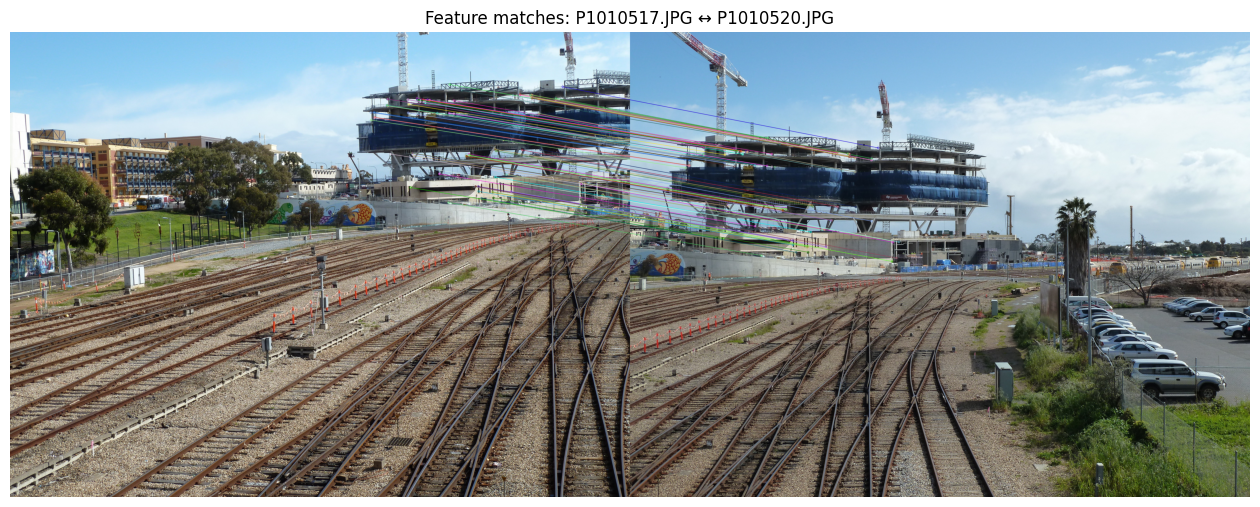

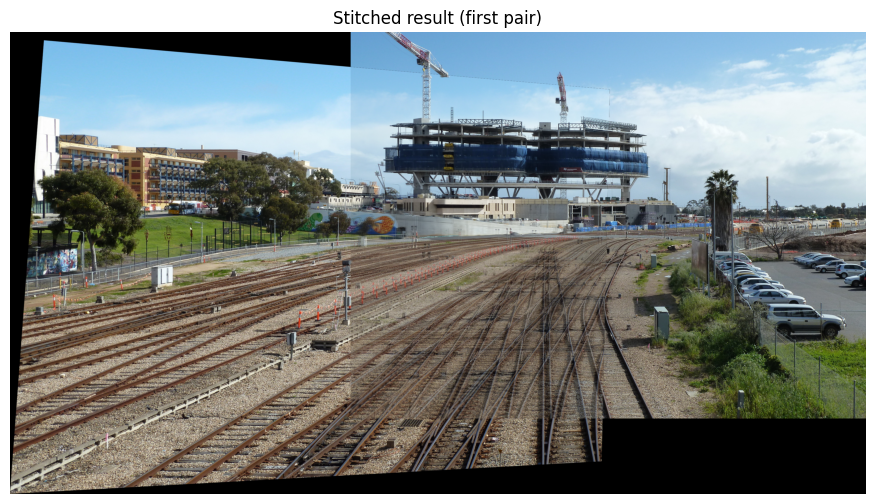

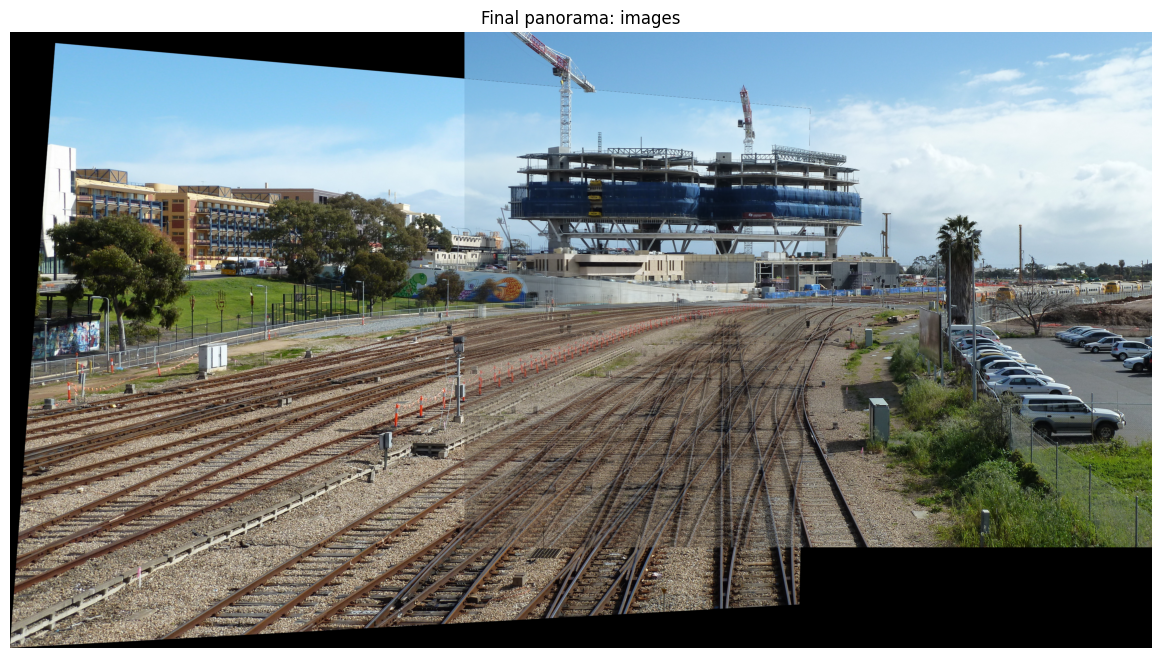

In [18]:
stitch_folder(folders[0])

Loaded 5 images from images2/case1
Good matches: 618
Homography found: True


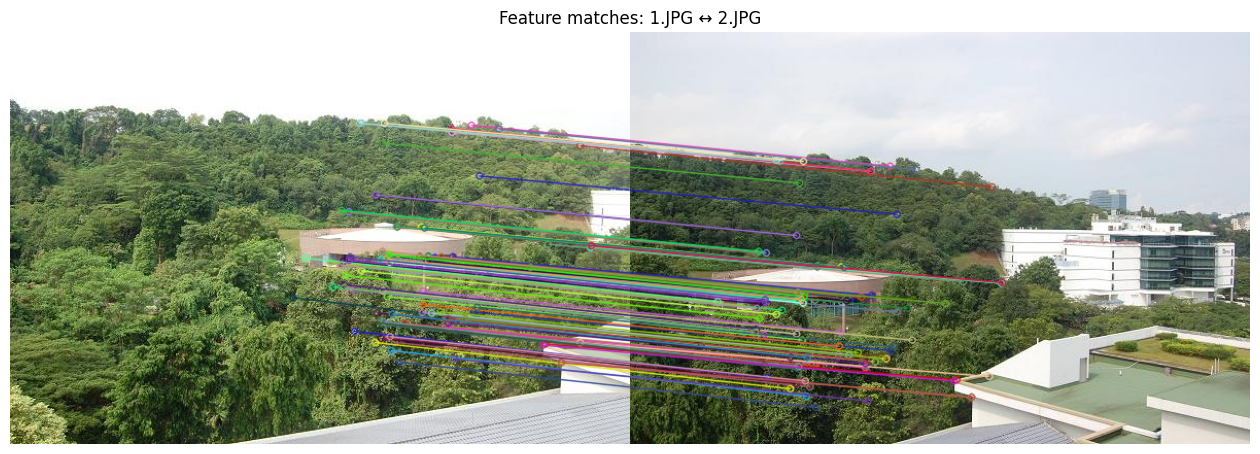

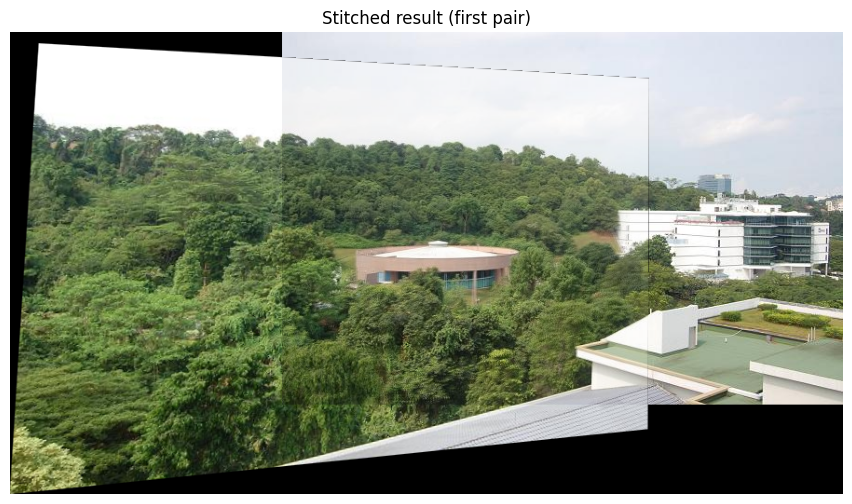

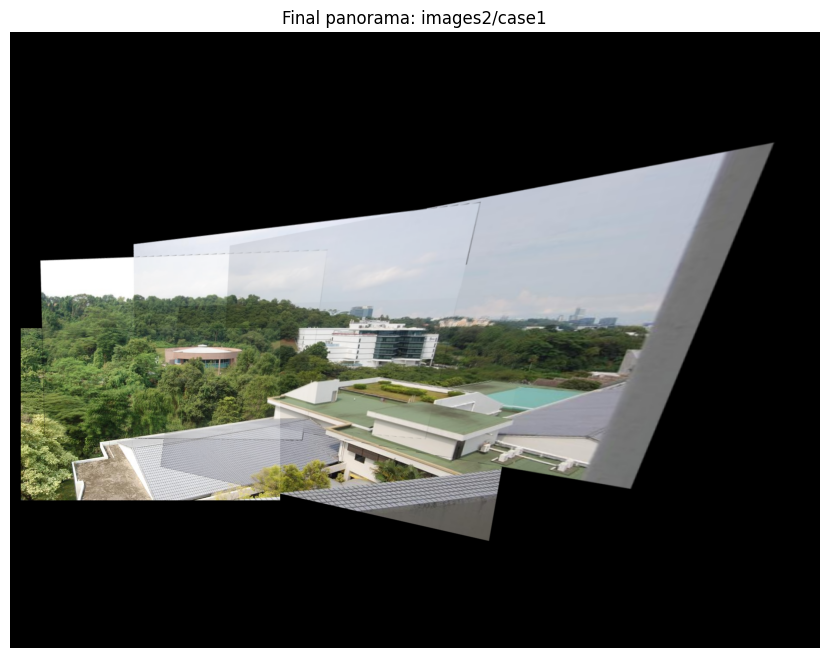

In [19]:
stitch_folder(folders[1])

Loaded 2 images from images3
Good matches: 369
Homography found: True


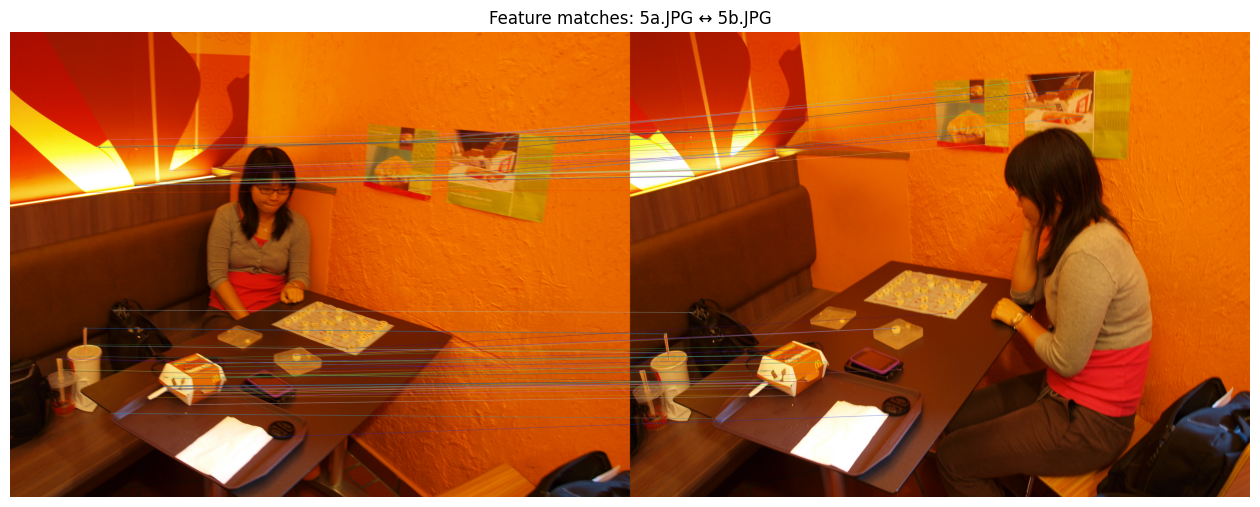

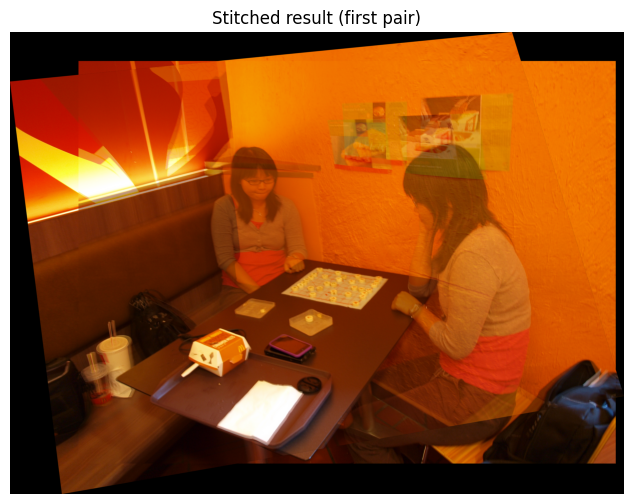

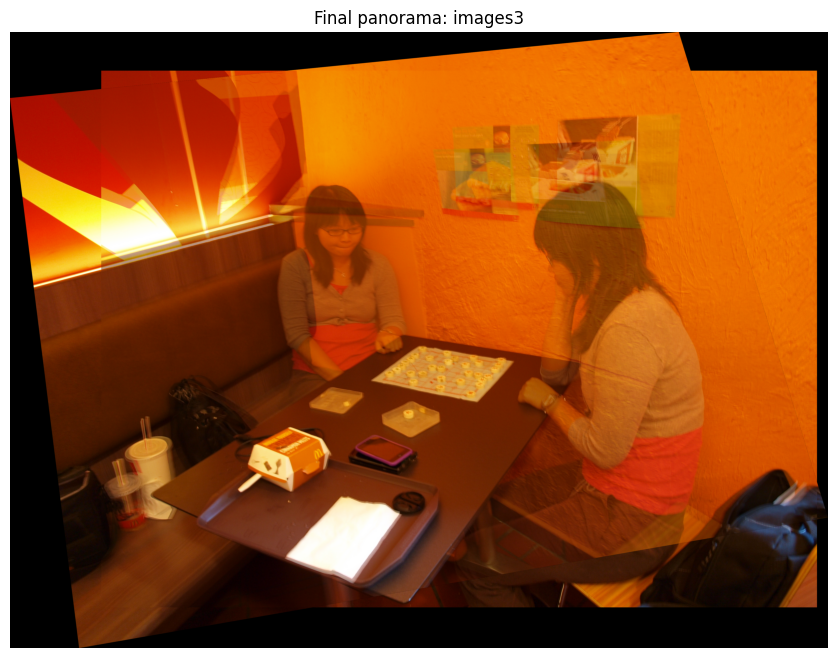

In [9]:
stitch_folder(folders[2])